<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-017-autoencoders-anomaly-detection.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 017 
<hr/>

# Lab 017 — Autoencoders and anomaly detection

Until now every image came with a label. Here we keep only the images $\{\mathbf x_i\}_{i=1}^n$ and let a network learn to **compress** them: an autoencoder squeezes each image through a narrow layer of $d$ numbers and rebuilds it. What it keeps in those $d$ numbers, and what it fails to rebuild, are both useful:

1. **The autoencoder:** encoder, decoder, bottleneck, and the pixel-by-pixel loss. A *linear* autoencoder rediscovers PCA.
2. **Dense autoencoders on MNIST** with $d=2$ (a latent space we can draw) and $d=16$.
3. **The latent space:** PCA and t-SNE of the 16 latent numbers, and k-means on them.
4. **Convolutional autoencoders:** a small one with $d=2$, and a deeper one with batch normalisation and $d=16$.
5. **Anomaly detection:** train on all digits except the 7s and use the reconstruction error to find the 7s. ROC curve and AUC, computed by hand.
6. **CIFAR-10:** an autoencoder on photographs, and photographs as an anomaly for the MNIST autoencoder.

Everything is written in **JAX**: the networks in `flax.nnx`, the optimiser in `optax`, one jit-compiled function per training epoch. The figures used on the Lecture 5 slides are written to `../beamer/figures/`, and the numbers quoted there to `../beamer/figures/numbers_lab017.json`.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The notebook runs on the **CPU** (the first code cell sets `JAX_PLATFORMS=cpu`); the training sets and numbers of epochs are chosen so that it finishes in a reasonable time on a multi-core CPU. With a GPU runtime you can delete that line and train the larger models on more data.
> 2. `jax`, `flax`, `optax`, `scikit-learn` and `matplotlib` are pre-installed in Colab.
> 3. The data are read from `data/MNIST_raw/` (the four `*-ubyte.gz` files) and `data/cifar-10-batches-py/`. If they are missing, the notebook downloads them.
> 4. Run the cells *in order*: later cells use variables defined earlier. If the state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import gzip, json, pickle, tarfile, time, urllib.request
from functools import partial
import numpy as np
import matplotlib.pyplot as plt

import jax, jax.numpy as jnp
import optax
from flax import nnx
import flax

from sklearn.manifold import TSNE          # used only to draw latent spaces (see the lab on PCA, t-SNE and k-means)
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
cmap10 = plt.get_cmap("tab10")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})

import os

OUT = "figures"; os.makedirs(OUT, exist_ok=True)                 # slide figures
os.makedirs(OUT, exist_ok=True)
def noframe(ax):                          # image panels: no ticks, no frame
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
def save(fig, name, **kw):
    fig.savefig(f"{OUT}/{name}", dpi=170, bbox_inches="tight", **kw)

nums = {}                                 # numbers quoted on the slides
t_start = time.time()
print("JAX", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__)
print("devices:", jax.devices())

JAX 0.11.0 | flax 0.12.8 | optax 0.2.6
devices: [CpuDevice(id=0)]


<hr/>
## 1. The data

MNIST: $28\times28$ grayscale digits, $60\,000$ for training and $10\,000$ for testing. Each image is a vector $\mathbf x\in[0,1]^{D}$ with $D=784$ pixels. The files are in the raw IDX format: a short big-endian header (a magic number, then the sizes), followed by one byte per pixel. We read them with `gzip` and `numpy` only.

For the plots of latent spaces we use a fixed random subset of $5000$ test images (`X5`, `y5`).

train (60000, 784) test (10000, 784) plot subset (5000, 784) | pixel range 0.0 1.0


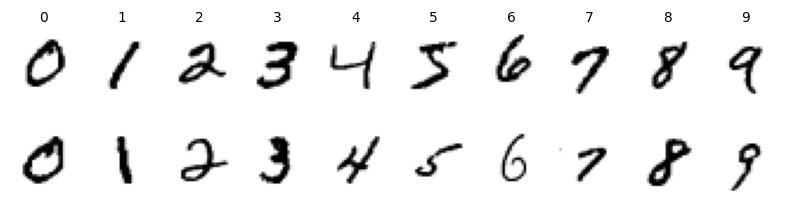

In [2]:
MNIST_DIR = "data/MNIST_raw"
MNIST_FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
               "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
if not all(os.path.exists(f"{MNIST_DIR}/{f}") for f in MNIST_FILES):
    os.makedirs(MNIST_DIR, exist_ok=True)
    for f in MNIST_FILES:
        urllib.request.urlretrieve(f"https://storage.googleapis.com/cvdf-datasets/mnist/{f}", f"{MNIST_DIR}/{f}")

def read_idx(path):
    with gzip.open(path, "rb") as fh:
        data = fh.read()
    ndim = data[3]                                                  # 3 for images, 1 for labels
    shape = np.frombuffer(data[4:4 + 4 * ndim], dtype=">i4")        # big-endian int32 sizes
    return np.frombuffer(data[4 + 4 * ndim:], dtype=np.uint8).reshape(shape)

Xtr = read_idx(f"{MNIST_DIR}/{MNIST_FILES[0]}").reshape(-1, 784).astype(np.float32) / 255.0
ytr = read_idx(f"{MNIST_DIR}/{MNIST_FILES[1]}").astype(np.int32)
Xte = read_idx(f"{MNIST_DIR}/{MNIST_FILES[2]}").reshape(-1, 784).astype(np.float32) / 255.0
yte = read_idx(f"{MNIST_DIR}/{MNIST_FILES[3]}").astype(np.int32)

rng = np.random.default_rng(0)
sel = rng.choice(len(Xte), 5000, replace=False)                     # fixed subset of test digits for plots
X5, y5 = Xte[sel], yte[sel]
print("train", Xtr.shape, "test", Xte.shape, "plot subset", X5.shape, "| pixel range", Xtr.min(), Xtr.max())

fig, axs = plt.subplots(2, 10, figsize=(9, 2.1))
for d in range(10):
    for r in range(2):
        axs[r, d].imshow(Xtr[np.flatnonzero(ytr == d)[r]].reshape(28, 28), cmap="gray_r"); axs[r, d].axis("off")
    axs[0, d].set_title(str(d), fontsize=9)
plt.show()

**JAX idiom: arrays on the device.** `jnp.asarray` copies a NumPy array to the default device (here the CPU; on a GPU runtime, the GPU). We do this once for the whole training set. Later, a minibatch is taken *on the device* by indexing, `X[idx]`, so on a GPU no data travel between host and device during training. JAX arrays are immutable: we never modify them in place, we create new ones.

In [3]:
Xtr_d = jnp.asarray(Xtr)                 # (60000, 784) on the default device
Xte_d = jnp.asarray(Xte)
X5_d = jnp.asarray(X5)
print(Xtr_d.devices(), Xtr_d.dtype, f"{Xtr_d.nbytes / 1e6:.0f} MB")

{CpuDevice(id=0)} float32 188 MB


<hr/>
## 2. The autoencoder

An autoencoder is two neural networks trained together:

* an **encoder** $E_{\boldsymbol\theta_E}:\mathbb R^{D}\to\mathbb R^{d}$ with $D$ inputs (the size of the data, $784$ pixels), $d$ outputs (the latent-space size, chosen by us) and its own parameters $\boldsymbol\theta_E$ (weights and biases). Its output $\mathbf z=E_{\boldsymbol\theta_E}(\mathbf x)$ is the **latent vector**;
* a **decoder** $G_{\boldsymbol\theta_D}:\mathbb R^{d}\to\mathbb R^{D}$ with $d$ inputs, $D$ outputs and its own parameters $\boldsymbol\theta_D$. Its output $\hat{\mathbf x}=G_{\boldsymbol\theta_D}(\mathbf z)$ is the **reconstruction**.

$$
\mathbf x\in\mathbb R^{784}\ \xrightarrow{\ E_{\boldsymbol\theta_E}\ }\ \mathbf z\in\mathbb R^{d}\ \xrightarrow{\ G_{\boldsymbol\theta_D}\ }\ \hat{\mathbf x}\in\mathbb R^{784}
$$

### The loss, pixel by pixel

There are no labels: every input is its own target. The loss compares each image with its reconstruction **pixel by pixel**,
$$
\mathcal L(\boldsymbol\theta_E,\boldsymbol\theta_D)=\frac1n\sum_{i=1}^{n}\underbrace{\frac1D\sum_{j=1}^{D}\big(x_{ij}-\hat x_{ij}\big)^2}_{e(\mathbf x_i)},\qquad \hat{\mathbf x}_i=G_{\boldsymbol\theta_D}\big(E_{\boldsymbol\theta_E}(\mathbf x_i)\big),
$$
with $i$ the image and $j$ the pixel. Two levels of averaging appear here, and both are used below:

* $e(\mathbf x)=\frac1D\lVert\mathbf x-\hat{\mathbf x}\rVert^2$ is the **reconstruction error of one image**, the mean of the per-pixel squared differences $(x_j-\hat x_j)^2$. A map of these $784$ numbers shows *where* the image is rebuilt badly. Later, $e(\mathbf x)$ will be our **anomaly score**.
* $\mathcal L$, the average of $e$ over the images, is the **mean squared error (MSE)** over all $n\cdot D$ pixel values. It is the number we minimise, and the number we report as the "test MSE".

$\mathcal L=0$ only if every pixel of every image is rebuilt exactly. The MSE treats each pixel as an independent Gaussian measurement with a fixed noise: up to constants, $\mathcal L$ is the negative log-likelihood of $p(\mathbf x\mid\mathbf z)=\prod_j\mathcal N(x_j;\hat x_j,\sigma^2)$. Other per-pixel losses (for example the binary cross-entropy, a Bernoulli model of each pixel) are equally valid choices.

$\boldsymbol\theta_E$ and $\boldsymbol\theta_D$ are updated together by gradient descent; the gradient flows from the loss through the decoder into the encoder (backpropagation).

### The bottleneck is a compression

If $d\ll D$, the decoder has to rebuild $784$ pixels from only $d$ numbers. The encoder must therefore put into $\mathbf z$ the features the decoder needs most: the bottleneck is a **lossy compression** with ratio $D/d$ ($49$ for $d=16$). The loss does not ask for anything else, but similar images tend to get nearby latent vectors, because the decoder must rebuild them alike. The space of all $\mathbf z$ is the **latent space**: a learned, low-dimensional description of the data.

### A linear autoencoder is PCA

Take a *linear* encoder and decoder, $\mathbf z=W_E(\mathbf x-\bar{\mathbf x})$ and $\hat{\mathbf x}=\bar{\mathbf x}+W_D\mathbf z$, with $W_E\in\mathbb R^{d\times D}$, $W_D\in\mathbb R^{D\times d}$ and $\bar{\mathbf x}$ the mean image. The reconstruction $\hat{\mathbf x}-\bar{\mathbf x}=W_DW_E(\mathbf x-\bar{\mathbf x})$ is a matrix of rank at most $d$ applied to the centred data. Stacking the centred images as rows of $X_c\in\mathbb R^{n\times D}$, the loss is $\frac{1}{nD}\lVert X_c-X_cW_E^\top W_D^\top\rVert_F^2$, and the best rank-$d$ approximation of $X_c$ in the Frobenius norm is given by its truncated singular value decomposition (Eckart–Young theorem). In other words: at the minimum, $W_DW_E$ is the orthogonal projector onto the span of the **first $d$ principal components** $\mathbf v_1,\dots,\mathbf v_d$ (the leading eigenvectors of the covariance matrix $C=\frac1n X_c^\top X_c$), and the loss equals the PCA reconstruction error
$$
\mathcal L_{\rm PCA}(d)=\frac1D\sum_{a>d}\lambda_a ,
$$
the sum of the discarded eigenvalues of $C$. The linear autoencoder finds the same *subspace* as PCA, but not the same axes: any invertible $A$ gives the same reconstruction with $W_E\to AW_E$, $W_D\to W_DA^{-1}$. With non-linear activations the autoencoder can follow *curved* low-dimensional structure, which a projection cannot. We check both statements numerically in Section 4.

<hr/>
## 3. Autoencoders in `flax.nnx`

The architecture of the dense autoencoder: layers $784\to256\to64\to d$ for the encoder and $d\to64\to256\to784$ for the decoder, ReLU activations, and a **sigmoid** at the output so that $\hat x_j\in(0,1)$, like the pixels.

**flax idiom: `nnx.Module`.** A network is a Python class. Its layers are created in `__init__` and stored as attributes (a list of layers is wrapped in `nnx.List`, so that flax sees the layers inside it); `__call__` describes the forward pass. `nnx.Linear(n_in, n_out, rngs=rngs)` creates a weight matrix and a bias, initialised at random.

**JAX idiom: explicit random numbers.** JAX has no hidden global random state. Every random operation receives a **key**, and the same key always gives the same numbers. `nnx.Rngs(seed)` is a small key generator that each layer asks for a fresh key; `jax.random.key(seed)` creates a key directly, and `jax.random.split(key)` turns one key into new independent ones. Fixing the seeds fixes the whole run.

The encoder and decoder are kept as two separate sub-networks, so that we can call them separately: `model.encode(x)` gives $\mathbf z$, `model.decode(z)` gives $\hat{\mathbf x}$. Every model below accepts an argument `train`; it matters only for batch normalisation (Section 6).

In [4]:
class DenseAE(nnx.Module):
    """Dense autoencoder: D -> hidden[0] -> hidden[1] -> d -> hidden[1] -> hidden[0] -> D."""
    def __init__(self, d, D=784, hidden=(256, 64), *, rngs):
        h1, h2 = hidden
        self.enc = nnx.List([nnx.Linear(D, h1, rngs=rngs), nnx.Linear(h1, h2, rngs=rngs), nnx.Linear(h2, d, rngs=rngs)])
        self.dec = nnx.List([nnx.Linear(d, h2, rngs=rngs), nnx.Linear(h2, h1, rngs=rngs), nnx.Linear(h1, D, rngs=rngs)])

    def encode(self, x, train=False):
        for layer in self.enc[:-1]:
            x = nnx.relu(layer(x))
        return self.enc[-1](x)                       # linear last layer: z can take any real value

    def decode(self, z, train=False):
        for layer in self.dec[:-1]:
            z = nnx.relu(layer(z))
        return nnx.sigmoid(self.dec[-1](z))          # pixels in (0, 1)

    def __call__(self, x, train=False):
        return self.decode(self.encode(x, train), train)

def n_params(model):
    return sum(p.size for p in jax.tree_util.tree_leaves(nnx.state(model, nnx.Param)))

demo = DenseAE(d=16, rngs=nnx.Rngs(0))
print("parameters of the dense autoencoder (d = 16):", n_params(demo))
print("z for two images:", demo.encode(X5_d[:2]).shape, "| reconstruction:", demo(X5_d[:2]).shape)

parameters of the dense autoencoder (d = 16): 437664


z for two images: (2, 16) | reconstruction: (2, 784)


### Training: one compiled function per epoch

The training loop is the same for every autoencoder in this notebook, so we write it once. Four idioms appear:

* **`nnx.split` / `nnx.merge`.** JAX transformations (`jit`, `grad`, `scan`) work on *pure functions of arrays*. `nnx.split(model, nnx.Param, ...)` separates a model into a static description of its structure (`graphdef`), the trainable parameters (`params`) and everything else (`rest`, e.g. the running statistics of batch normalisation). `nnx.merge(graphdef, params, rest)` builds the model back. Inside the loss function we merge, run the model, and return the loss.
* **`optax`.** An optimiser is a pair of pure functions: `tx.init(params)` creates its state (for Adam: running averages of the gradient and of its square), `tx.update(grads, state, params)` returns the parameter updates and the new state; `optax.apply_updates` adds them.
* **`jax.value_and_grad`.** Turns the loss function into one that returns the loss *and* its gradient with respect to the first argument, `params`.
* **`jax.lax.scan` over an epoch.** At the start of an epoch we draw a random permutation of the $n$ training images and cut it into $n_b$ rows of `batch_size` indices (the last incomplete batch is dropped). `lax.scan(step, carry, idx)` applies `step` to each row in turn, carrying the parameters and optimiser state from one minibatch to the next. Combined with **`jax.jit`**, the whole epoch, hundreds of gradient steps, is compiled by XLA into a single program: no Python loop over minibatches. The data `X` are an argument of the compiled function, not a constant baked into it.

In [5]:
def mse_per_image(x, xhat):
    """Reconstruction error e(x) = (1/D) sum_j (x_j - xhat_j)^2, one number per image."""
    return jnp.mean((x - xhat) ** 2, axis=tuple(range(1, x.ndim)))

def train_autoencoder(model, X, epochs, seed, batch_size=256, lr=1e-3, verbose=True):
    """Adam on the pixel-wise MSE; one jit-compiled lax.scan per epoch. Returns the trained model and the loss per epoch."""
    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.adam(lr)
    opt_state = tx.init(params)
    n_batches = X.shape[0] // batch_size

    def loss_fn(params, rest, xb):
        m = nnx.merge(graphdef, params, rest, copy=True)
        loss = jnp.mean(mse_per_image(xb, m(xb, train=True)))
        _, _, new_rest = nnx.split(m, nnx.Param, ...)           # updated batch statistics (if any)
        return loss, new_rest

    @jax.jit
    def train_epoch(params, rest, opt_state, X, key):
        idx = jax.random.permutation(key, X.shape[0])[: n_batches * batch_size].reshape(n_batches, batch_size)
        def step(carry, batch_idx):
            params, rest, opt_state = carry
            (loss, rest), grads = jax.value_and_grad(loss_fn, has_aux=True)(params, rest, X[batch_idx])
            updates, opt_state = tx.update(grads, opt_state, params)
            return (optax.apply_updates(params, updates), rest, opt_state), loss
        (params, rest, opt_state), losses = jax.lax.scan(step, (params, rest, opt_state), idx)
        return params, rest, opt_state, losses.mean()

    key, history, t0 = jax.random.key(seed), [], time.time()
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, rest, opt_state, loss = train_epoch(params, rest, opt_state, X, sub)
        history.append(float(loss))
        if verbose and (ep == 0 or (ep + 1) % 5 == 0):
            print(f"  epoch {ep + 1:3d}: training loss {history[-1]:.5f}   ({time.time() - t0:5.1f} s)")
    nnx.update(model, params, rest)                              # write the trained values back into the model
    return model, np.array(history)

**Evaluation.** For trained models we use **`nnx.jit`**, the flax version of `jax.jit` that accepts a module as an argument. Large data sets are processed in chunks of $1000$ images, which keeps the memory small even for the convolutional networks. `train=False` everywhere: evaluation never changes the model.

In [6]:
@nnx.jit
def _encode(model, x):
    return model.encode(x, train=False)

@nnx.jit
def _reconstruct(model, x):
    return model(x, train=False)

def in_chunks(fn, model, X, chunk=1000):
    return jnp.concatenate([fn(model, X[i:i + chunk]) for i in range(0, X.shape[0], chunk)])

def encode(model, X):      return np.asarray(in_chunks(_encode, model, X))
def reconstruct(model, X): return np.asarray(in_chunks(_reconstruct, model, X))
def errors(model, X):      return np.asarray(mse_per_image(X, in_chunks(_reconstruct, model, X)))

<hr/>
## 4. Dense autoencoders on MNIST

### A two-dimensional latent space

With $d=2$ we can draw the latent space directly. We train for $15$ epochs with Adam (learning rate $10^{-3}$, minibatches of $256$). The labels are **not** used for training; they only colour the points of the plot.

  epoch   1: training loss 0.06439   (  2.3 s)


  epoch   5: training loss 0.04262   (  7.5 s)


  epoch  10: training loss 0.03969   ( 14.2 s)


  epoch  15: training loss 0.03826   ( 22.0 s)


test MSE (d = 2): 0.0389


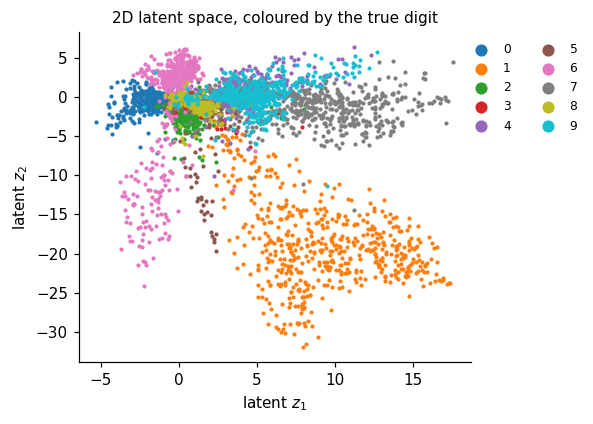

In [7]:
ae2, hist2 = train_autoencoder(DenseAE(d=2, rngs=nnx.Rngs(0)), Xtr_d, epochs=15, seed=0)
L2 = encode(ae2, X5_d)                                             # (5000, 2)
nums["ae2_test_mse"] = float(errors(ae2, X5_d).mean())
print("test MSE (d = 2):", round(nums["ae2_test_mse"], 4))

fig, ax = plt.subplots(figsize=(4.6, 3.9))
for d in range(10):
    m = y5 == d
    ax.scatter(L2[m, 0], L2[m, 1], s=3, color=cmap10(d), label=str(d))
ax.legend(markerscale=4, fontsize=8, ncol=2, loc="upper right", bbox_to_anchor=(1.3, 1))
ax.set_xlabel("latent $z_1$"); ax.set_ylabel("latent $z_2$")
ax.set_title("2D latent space, coloured by the true digit", fontsize=10)
save(fig, "gen_ae_latent_mnist.png"); plt.show()

Some digits occupy their own region of the plane (look at the 0s and the 1s), others overlap. The plane is not a map with a fixed scale: the encoder is free to stretch it, and another seed rotates or mirrors it.

### Sixteen latent numbers

With $d=16$ the reconstructions become much sharper. The figure shows test digits (top), their reconstructions from $16$ numbers (middle) and from $2$ numbers (bottom).

  epoch   1: training loss 0.05061   (  2.3 s)


  epoch   5: training loss 0.01610   (  8.1 s)


  epoch  10: training loss 0.01347   ( 14.2 s)


  epoch  15: training loss 0.01227   ( 19.5 s)
test MSE (d = 16): 0.0121 | (d = 2): 0.0389


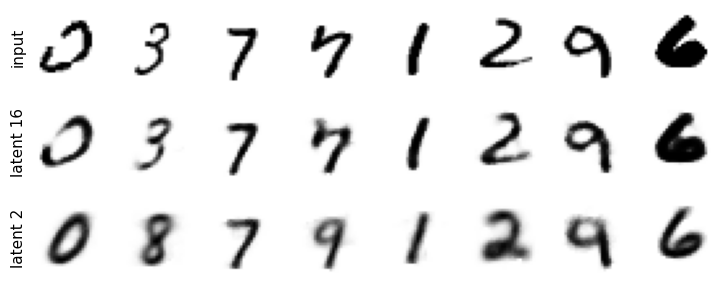

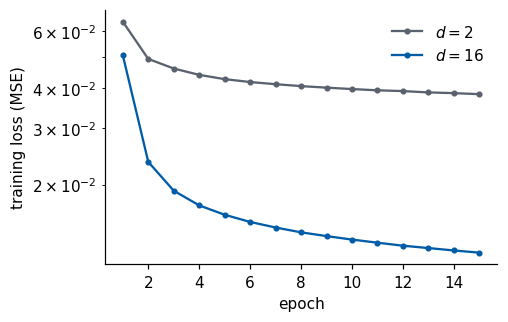

In [8]:
ae16, hist16 = train_autoencoder(DenseAE(d=16, rngs=nnx.Rngs(1)), Xtr_d, epochs=15, seed=1)
err16_X5 = errors(ae16, X5_d)
nums["ae16_test_mse"] = float(err16_X5.mean())
print("test MSE (d = 16):", round(nums["ae16_test_mse"], 4), "| (d = 2):", round(nums["ae2_test_mse"], 4))

show = X5[:8]
r16, r2 = reconstruct(ae16, X5_d[:8]), reconstruct(ae2, X5_d[:8])
fig, axs = plt.subplots(3, 8, figsize=(8, 3.2))
for j in range(8):
    for i, (img, lab) in enumerate([(show[j], "input"), (r16[j], "latent 16"), (r2[j], "latent 2")]):
        axs[i, j].imshow(img.reshape(28, 28), cmap="gray_r"); noframe(axs[i, j])
        if j == 0: axs[i, j].set_ylabel(lab, fontsize=10)
save(fig, "gen_ae_reconstructions.png"); plt.show()

fig, ax = plt.subplots(figsize=(4.6, 3.0))
ax.plot(np.arange(1, 16), hist2, "o-", color=UJGray, ms=3, label="$d=2$")
ax.plot(np.arange(1, 16), hist16, "o-", color=UJBlue, ms=3, label="$d=16$")
ax.set_xlabel("epoch"); ax.set_ylabel("training loss (MSE)"); ax.set_yscale("log"); ax.legend()
plt.show()

### Comparison with PCA, and the linear autoencoder

PCA is the best *linear* compression to $d$ numbers. We compute it in JAX from the eigen-decomposition of the $784\times784$ covariance matrix of the training images (`jnp.linalg.eigh` returns the eigenvalues in ascending order, so we reverse them), project the test images on the first $d$ eigenvectors and rebuild them:
$$
\hat{\mathbf x}^{\rm PCA}=\bar{\mathbf x}+\sum_{a=1}^{d}\big(\mathbf v_a\cdot(\mathbf x-\bar{\mathbf x})\big)\,\mathbf v_a .
$$
Then we train a **linear** autoencoder with $d=2$ (no activations, no sigmoid, input centred with the mean image) and compare it with PCA in two ways: its test MSE, and the **principal angles** between the plane spanned by the columns of its decoder $W_D$ and the plane of $\mathbf v_1,\mathbf v_2$. If $Q_{\rm AE}$ and $Q_{\rm PCA}$ are orthonormal bases of the two planes, the singular values of $Q_{\rm AE}^\top Q_{\rm PCA}$ are the cosines of the principal angles; both angles are zero exactly when the planes coincide.

In [9]:
xbar = Xtr_d.mean(0)
C = (Xtr_d - xbar).T @ (Xtr_d - xbar) / Xtr_d.shape[0]       # 784 x 784 covariance matrix
lam, V = jnp.linalg.eigh(C)
lam, V = lam[::-1], V[:, ::-1]                               # descending eigenvalues, eigenvectors as columns

def pca_reconstruct(X, d):
    Vd = V[:, :d]
    return xbar + ((X - xbar) @ Vd) @ Vd.T

for d in (2, 16):
    nums[f"pca{d}_test_mse"] = float(mse_per_image(X5_d, pca_reconstruct(X5_d, d)).mean())
    nums[f"pca{d}_train_mse_from_eigenvalues"] = float(lam[d:].sum() / 784)
print("test MSE    PCA       dense autoencoder")
print(f"d =  2      {nums['pca2_test_mse']:.4f}    {nums['ae2_test_mse']:.4f}")
print(f"d = 16      {nums['pca16_test_mse']:.4f}    {nums['ae16_test_mse']:.4f}")
print("PCA training MSE from the discarded eigenvalues, d = 2 and 16:",
      round(nums["pca2_train_mse_from_eigenvalues"], 4), round(nums["pca16_train_mse_from_eigenvalues"], 4))

test MSE    PCA       dense autoencoder
d =  2      0.0557    0.0389
d = 16      0.0268    0.0121
PCA training MSE from the discarded eigenvalues, d = 2 and 16: 0.056 0.0273


In [10]:
class LinearAE(nnx.Module):
    """z = W_E (x - xbar),  xhat = xbar + W_D z  (no biases, no activations)."""
    def __init__(self, d, mean, D=784, *, rngs):
        self.mean = nnx.Variable(mean)                       # a fixed, non-trainable array stored in the model
        self.WE = nnx.Linear(D, d, use_bias=False, rngs=rngs)
        self.WD = nnx.Linear(d, D, use_bias=False, rngs=rngs)
    def encode(self, x, train=False): return self.WE(x - self.mean[...])
    def decode(self, z, train=False): return self.mean[...] + self.WD(z)
    def __call__(self, x, train=False): return self.decode(self.encode(x))

lin2, hist_lin = train_autoencoder(LinearAE(2, xbar, rngs=nnx.Rngs(2)), Xtr_d, epochs=30, seed=2, lr=3e-3, verbose=False)
nums["linear_ae2_test_mse"] = float(errors(lin2, X5_d).mean())

WD = lin2.WD.kernel[...].T                                   # (784, 2): the decoder columns span the AE plane
Q_ae, _ = jnp.linalg.qr(WD)
cosines = jnp.linalg.svd(Q_ae.T @ V[:, :2], compute_uv=False)
angles = np.degrees(np.arccos(np.clip(np.asarray(cosines), -1, 1)))
nums["linear_ae2_principal_angles_deg"] = [float(a) for a in angles]
print(f"linear AE (d = 2): test MSE {nums['linear_ae2_test_mse']:.4f}   PCA (d = 2): {nums['pca2_test_mse']:.4f}")
print("principal angles between the linear-AE plane and the PCA plane (degrees):", np.round(angles, 2))
print("first decoder column . v_1 and v_2 (normalised):", np.round(np.asarray(WD[:, 0] / jnp.linalg.norm(WD[:, 0]) @ V[:, :2]), 3))

linear AE (d = 2): test MSE 0.0557   PCA (d = 2): 0.0557
principal angles between the linear-AE plane and the PCA plane (degrees): [0.76 0.97]


first decoder column . v_1 and v_2 (normalised): [-0.494 -0.869]


The linear autoencoder reaches the PCA error and its plane is (up to a small angle) the plane of the first two principal components; its two decoder columns, however, are not $\mathbf v_1$ and $\mathbf v_2$ themselves, only some basis of the same plane. The non-linear autoencoder with the same $d$ goes below the PCA error: it compresses better than any projection.

**flax idiom: `nnx.Variable`.** The mean image is stored in the model as an `nnx.Variable`, not an `nnx.Param`. Our training function differentiates only `nnx.Param`, so the mean stays fixed. `variable[...]` reads its value.

**Try it.** Train the linear autoencoder with $d=16$ and compare with `pca16_test_mse`. Then add a ReLU between its encoder and decoder layers: what happens to the error?

### One digit through the autoencoder

The images of the autoencoder diagram on the slides: a clearly written test digit (the 3 that the $d=16$ autoencoder rebuilds best), its $16$ latent numbers, and its reconstruction.

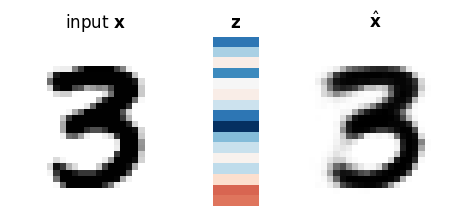

test digit index 4495 | reconstruction error 0.0042 | latent vector: [ -9.64  -4.28   0.9   -8.47  -0.03   0.85  -2.84  -9.59 -13.27  -5.78
  -3.     0.47  -3.34   2.23   7.69   7.12]


In [11]:
threes = np.flatnonzero(y5 == 3)
k3 = threes[np.argmin(err16_X5[threes])]                     # the 3 with the smallest reconstruction error
z3 = encode(ae16, X5_d[k3:k3 + 1])[0]
x_out = reconstruct(ae16, X5_d[k3:k3 + 1])[0]

for arr, name in [(X5[k3], "gen_ae_in.png"), (x_out, "gen_ae_out.png")]:
    fig = plt.figure(figsize=(2, 2)); plt.imshow(arr.reshape(28, 28), cmap="gray_r"); plt.axis("off")
    save(fig, name, pad_inches=0.02); plt.close(fig)
fig, ax = plt.subplots(figsize=(0.6, 4.0))
ax.imshow(z3[:, None], cmap="RdBu_r", vmin=-np.abs(z3).max(), vmax=np.abs(z3).max(), aspect="auto")
for i, v in enumerate(z3):
    ax.text(0, i, f"{v:.1f}", ha="center", va="center", fontsize=7)
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values(): s.set_visible(True)
save(fig, "gen_ae_z.png", pad_inches=0.02); plt.close(fig)

fig, axs = plt.subplots(1, 3, figsize=(5.4, 2.0), gridspec_kw=dict(width_ratios=[1, 0.25, 1]))
axs[0].imshow(X5[k3].reshape(28, 28), cmap="gray_r"); axs[0].set_title("input $\\mathbf{x}$")
axs[1].imshow(z3[:, None], cmap="RdBu_r", vmin=-np.abs(z3).max(), vmax=np.abs(z3).max(), aspect="auto"); axs[1].set_title("$\\mathbf{z}$")
axs[2].imshow(x_out.reshape(28, 28), cmap="gray_r"); axs[2].set_title("$\\hat{\\mathbf{x}}$")
for a in axs: noframe(a)
plt.show()
print("test digit index", k3, "| reconstruction error", round(float(err16_X5[k3]), 4), "| latent vector:", np.round(z3, 2))

### The loss, pixel by pixel

The per-pixel squared differences $(x_j-\hat x_j)^2$ of this digit; their mean is the reconstruction error $e(\mathbf x)$ of the image, and the mean of $e$ over all images is the loss $\mathcal L$.

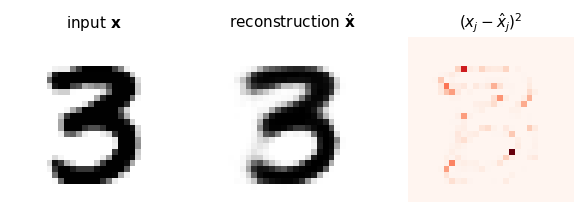

mean of the error map (the reconstruction error of this image): 0.0042


In [12]:
err_map = (X5[k3] - x_out) ** 2
fig, axs = plt.subplots(1, 3, figsize=(6.6, 2.3))
for a, im, t, cm in zip(axs, [X5[k3], x_out, err_map],
                        [r"input $\mathbf{x}$", r"reconstruction $\hat{\mathbf{x}}$", r"$(x_j - \hat{x}_j)^2$"],
                        ["gray_r", "gray_r", "Reds"]):
    a.imshow(im.reshape(28, 28), cmap=cm); a.set_title(t, fontsize=10); a.axis("off")
save(fig, "gen_ae_loss_map.png"); plt.show()
print("mean of the error map (the reconstruction error of this image):", round(float(err_map.mean()), 4))

<hr/>
## 5. Looking into the latent space

Every test image is now described by $16$ latent numbers. We treat them as a new data set: a linear projection with PCA (computed in JAX with an SVD of the centred latent vectors) and a non-linear map with t-SNE. The colours are the true digits, used only for plotting.

Do the digits form clusters *in the latent space itself*? We run k-means ($k=10$) directly on the $16$ latent numbers and on their t-SNE map, and compare with k-means on the pixels (on $50$ PCA components). The agreement with the true digits is measured by the adjusted Rand index (ARI: $1$ for a perfect match, about $0$ for a random assignment).

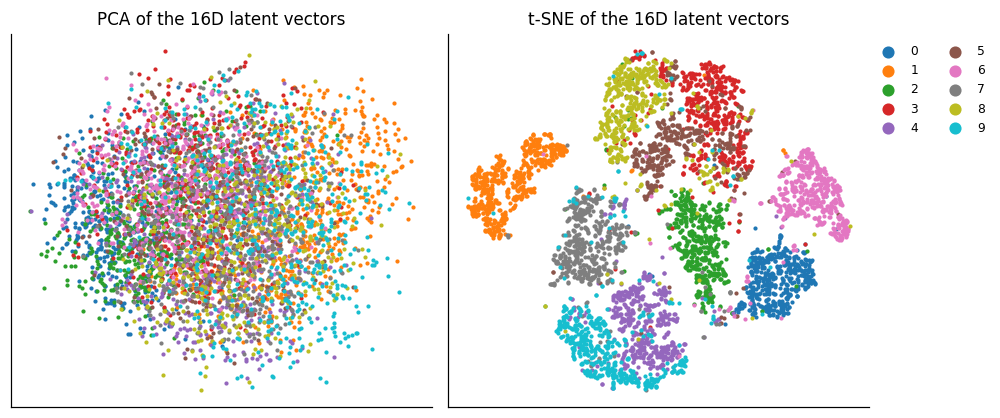

k-means (k = 10), adjusted Rand index with the true digits:
  pixels, 50 PCA components : 0.384
  16 latent numbers, directly: 0.284
  t-SNE map of the 16 latent numbers: 0.696


In [13]:
def pca_2d(Z):
    """Projection on the first two principal components, via the SVD of the centred data (in JAX)."""
    Zc = jnp.asarray(Z) - jnp.mean(jnp.asarray(Z), 0)
    _, s, Vt = jnp.linalg.svd(Zc, full_matrices=False)
    return np.asarray(Zc @ Vt[:2].T), float((s[:2] ** 2).sum() / (s ** 2).sum())

def tsne(Z):
    return TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(np.asarray(Z))

def kmeans_ari(Z, labels):
    return float(adjusted_rand_score(labels, KMeans(10, n_init=10, random_state=0).fit(np.asarray(Z)).labels_))

def plot_two_maps(P_left, P_right, titles, labels, names=None):
    fig, axs = plt.subplots(1, 2, figsize=(9, 3.9))
    for a, P2, t in zip(axs, [P_left, P_right], titles):
        for c in range(10):
            m = labels == c
            a.scatter(P2[m, 0], P2[m, 1], s=3, color=cmap10(c), label=(names[c] if names else str(c)))
        a.set_title(t, fontsize=11); a.set_xticks([]); a.set_yticks([])
    axs[1].legend(markerscale=4, fontsize=8, ncol=2, loc="upper right", bbox_to_anchor=(1.3, 1))
    plt.tight_layout()
    return fig

L16 = encode(ae16, X5_d)                                     # (5000, 16)
L16_pca, _ = pca_2d(L16)
L16_tsne = tsne(L16)
fig = plot_two_maps(L16_pca, L16_tsne, ["PCA of the 16D latent vectors", "t-SNE of the 16D latent vectors"], y5)
save(fig, "gen_ae_latent16_maps.png"); plt.show()

Z50 = np.asarray((X5_d - xbar) @ V[:, :50])                  # the pixels, on 50 principal components
nums["pixels_pca50_kmeans_ari"] = kmeans_ari(Z50, y5)
nums["ae16_latent_kmeans_ari_direct"] = kmeans_ari(L16, y5)
nums["ae16_latent_kmeans_ari_tsne"] = kmeans_ari(L16_tsne, y5)
print("k-means (k = 10), adjusted Rand index with the true digits:")
print(f"  pixels, 50 PCA components : {nums['pixels_pca50_kmeans_ari']:.3f}")
print(f"  16 latent numbers, directly: {nums['ae16_latent_kmeans_ari_direct']:.3f}")
print(f"  t-SNE map of the 16 latent numbers: {nums['ae16_latent_kmeans_ari_tsne']:.3f}")

In the PCA projection the digits overlap: they differ along many of the $16$ directions, and any two of them show only part of it. The t-SNE map keeps the neighbours of each point and shows groups. k-means directly in the latent space does not recover the digits much better than on the pixels: the digits are kept in the latent space, but not as the round, equally sized groups that k-means looks for.

**Try it.** Repeat the analysis with the latent space of the $d=2$ autoencoder (`L2`), where no projection is needed. Is k-means better or worse there?

<hr/>
## 6. Convolutional autoencoders

### A small convolutional autoencoder, $d=2$

A dense layer sees an image as a flat list of $784$ numbers: it does not know which pixels are neighbours. A **convolutional** encoder uses the 2D structure, like the CNNs of Lecture 4. Here two convolutions with $3\times3$ kernels and stride $2$ ($28\to14\to7$ pixels, $16$ and $32$ channels), then dense layers $32\cdot7\cdot7\to128\to d$. The decoder mirrors it: dense layers back to $32\cdot7\cdot7$, then two **transposed convolutions** with stride $2$ ($7\to14\to28$), the last one with a single channel and a sigmoid.

**flax idiom: channels last.** `nnx.Conv` expects images of shape `(batch, height, width, channels)` (NHWC), unlike PyTorch's NCHW. Our MNIST images become `(n, 28, 28, 1)` with a reshape, which costs nothing. `nnx.ConvTranspose(..., strides=2, padding="SAME")` doubles the height and width exactly.

**Cost on a CPU.** A convolutional layer costs far more arithmetic per image than a dense layer of similar size, and its gradient even more. To keep the notebook fast on a CPU we use few channels and train the convolutional models on a random subset of the training images, for fewer epochs (`N_CONV`, `EPOCHS_CONV` below). To make up for the fewer images we use smaller minibatches of $64$: the same arithmetic per epoch, but four times as many gradient steps. The dense autoencoders above used all $60\,000$ images.

training images: 20000 | epochs: 8


  epoch   1: training loss 0.07243   (  7.4 s)


  epoch   5: training loss 0.04875   ( 34.8 s)


parameters: 413315


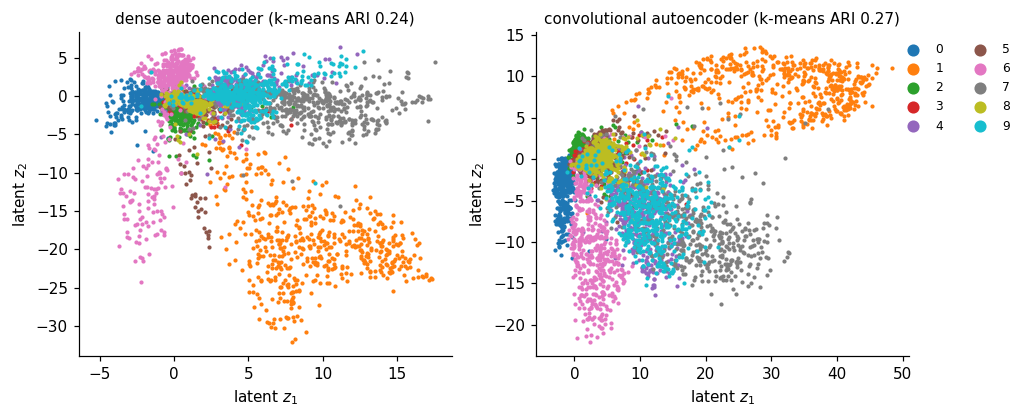

{'ae2_test_mse': 0.0389, 'cae2_test_mse': 0.0445, 'ae2_latent_kmeans_ari': 0.2409, 'cae2_latent_kmeans_ari': 0.2684}


In [14]:
class ConvAE(nnx.Module):
    def __init__(self, d=2, ch=(16, 32), *, rngs):
        c1, c2 = ch
        self.ch = ch
        self.c1 = nnx.Conv(1, c1, (3, 3), strides=2, padding=1, rngs=rngs)           # 28 -> 14
        self.c2 = nnx.Conv(c1, c2, (3, 3), strides=2, padding=1, rngs=rngs)          # 14 -> 7
        self.e1 = nnx.Linear(c2 * 7 * 7, 128, rngs=rngs)
        self.e2 = nnx.Linear(128, d, rngs=rngs)
        self.d1 = nnx.Linear(d, 128, rngs=rngs)
        self.d2 = nnx.Linear(128, c2 * 7 * 7, rngs=rngs)
        self.t1 = nnx.ConvTranspose(c2, c1, (3, 3), strides=2, padding="SAME", rngs=rngs)   # 7 -> 14
        self.t2 = nnx.ConvTranspose(c1, 1, (3, 3), strides=2, padding="SAME", rngs=rngs)    # 14 -> 28

    def encode(self, x, train=False):
        h = nnx.relu(self.c2(nnx.relu(self.c1(x))))
        return self.e2(nnx.relu(self.e1(h.reshape(h.shape[0], -1))))

    def decode(self, z, train=False):
        h = nnx.relu(self.d2(nnx.relu(self.d1(z)))).reshape(-1, 7, 7, self.ch[1])
        return nnx.sigmoid(self.t2(nnx.relu(self.t1(h))))

    def __call__(self, x, train=False):
        return self.decode(self.encode(x, train), train)

Xtr_img, X5_img = Xtr_d.reshape(-1, 28, 28, 1), X5_d.reshape(-1, 28, 28, 1)
N_CONV, EPOCHS_CONV = 20000, 8                              # training subset and epochs for the convolutional models
sub = np.random.default_rng(1).permutation(len(Xtr))[:N_CONV]
Xsub_img = Xtr_img[sub]
print("training images:", Xsub_img.shape[0], "| epochs:", EPOCHS_CONV)
cae2, hist_c2 = train_autoencoder(ConvAE(2, rngs=nnx.Rngs(3)), Xsub_img, epochs=EPOCHS_CONV, seed=3, batch_size=64)
print("parameters:", n_params(cae2))
Lc = encode(cae2, X5_img)
nums["cae2_test_mse"] = float(errors(cae2, X5_img).mean())
nums["ae2_latent_kmeans_ari"] = kmeans_ari(L2, y5)
nums["cae2_latent_kmeans_ari"] = kmeans_ari(Lc, y5)

fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.9))
for a, P2, t in zip(axs, [L2, Lc], [f"dense autoencoder (k-means ARI {nums['ae2_latent_kmeans_ari']:.2f})",
                                    f"convolutional autoencoder (k-means ARI {nums['cae2_latent_kmeans_ari']:.2f})"]):
    for c in range(10):
        m = y5 == c
        a.scatter(P2[m, 0], P2[m, 1], s=3, color=cmap10(c), label=str(c))
    a.set_title(t, fontsize=10); a.set_xlabel("latent $z_1$"); a.set_ylabel("latent $z_2$")
axs[1].legend(markerscale=4, fontsize=8, ncol=2, loc="upper right", bbox_to_anchor=(1.3, 1))
plt.tight_layout(); save(fig, "gen_ae_dense_vs_conv.png"); plt.show()
print({k: round(nums[k], 4) for k in ["ae2_test_mse", "cae2_test_mse", "ae2_latent_kmeans_ari", "cae2_latent_kmeans_ari"]})

With the same two latent numbers the convolutional encoder gives the higher ARI (printed above), although it saw only a third of the training images and has the larger test MSE: it compares neighbouring pixels, as a CNN does, and builds its two numbers from local strokes rather than from individual pixel positions. Note that the colours are not used in training; a better ARI is a by-product, not a goal, of the reconstruction loss.

### A deeper convolutional autoencoder, $d=16$

A deeper model: three convolutions ($8$, $16$, $32$ channels, the last two with stride $2$), each followed by **batch normalisation** and ReLU, then dense layers $32\cdot7\cdot7\to128\to16$. To save CPU time it is trained on a smaller subset (`N_DEEP` images, `EPOCHS_DEEP` epochs). The decoder mirrors it with transposed convolutions and ends with a $3\times3$ convolution to one channel and a sigmoid.

**Batch normalisation** rescales every channel to zero mean and unit variance over the current minibatch, then applies a learned scale and shift. During training it uses the minibatch statistics and updates running averages of them; at evaluation it uses the running averages, so that the output for one image does not depend on the other images in the batch. In flax the running averages are `nnx.BatchStat` variables, not parameters: they are not differentiated, they are part of `rest` in our training function and are carried through `lax.scan` next to the parameters. The argument `train` selects the mode (`use_running_average=not train`).

  epoch   1: training loss 0.07130   ( 10.4 s)


  epoch   5: training loss 0.01287   ( 44.8 s)


parameters: 419249


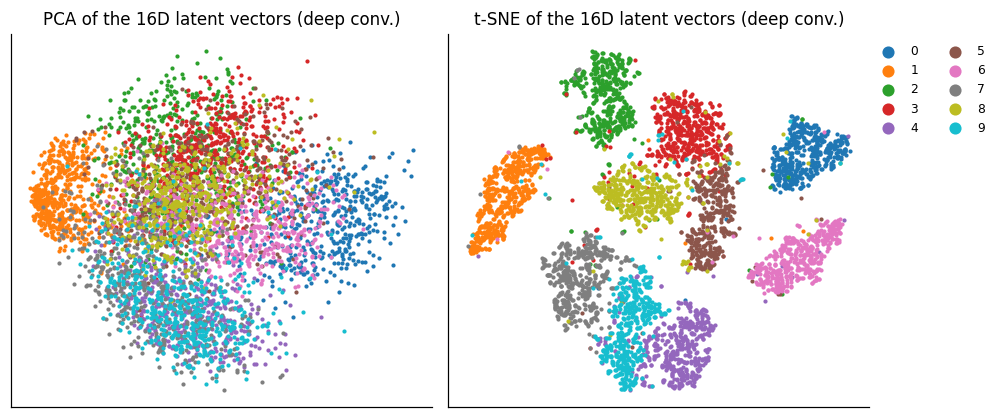

{'ae16_test_mse': 0.0121, 'dcae16_test_mse': 0.0121, 'dcae16_pca2_var': 0.3886, 'ae16_latent_kmeans_ari_direct': 0.2838, 'dcae16_kmeans_ari_direct': 0.4558, 'ae16_latent_kmeans_ari_tsne': 0.6963, 'dcae16_kmeans_ari_tsne': 0.8153}


In [15]:
class DeepConvAE(nnx.Module):
    def __init__(self, d=16, ch=(8, 16, 32), hidden=128, *, rngs):
        c1, c2, c3 = ch
        self.c3 = c3
        conv = lambda i, o, s: nnx.Conv(i, o, (3, 3), strides=s, padding=1, rngs=rngs)
        tconv = lambda i, o: nnx.ConvTranspose(i, o, (3, 3), strides=2, padding="SAME", rngs=rngs)
        self.enc_convs = nnx.List([conv(1, c1, 1), conv(c1, c2, 2), conv(c2, c3, 2)])     # 28 -> 28 -> 14 -> 7
        self.enc_bns = nnx.List([nnx.BatchNorm(c, rngs=rngs) for c in (c1, c2, c3)])
        self.e1, self.e2 = nnx.Linear(c3 * 7 * 7, hidden, rngs=rngs), nnx.Linear(hidden, d, rngs=rngs)
        self.d1, self.d2 = nnx.Linear(d, hidden, rngs=rngs), nnx.Linear(hidden, c3 * 7 * 7, rngs=rngs)
        self.dec_tconvs = nnx.List([tconv(c3, c2), tconv(c2, c1)])                       # 7 -> 14 -> 28
        self.dec_bns = nnx.List([nnx.BatchNorm(c, rngs=rngs) for c in (c2, c1)])
        self.out = conv(c1, 1, 1)

    def encode(self, x, train=False):
        for c, bn in zip(self.enc_convs, self.enc_bns):
            x = nnx.relu(bn(c(x), use_running_average=not train))
        return self.e2(nnx.relu(self.e1(x.reshape(x.shape[0], -1))))

    def decode(self, z, train=False):
        h = nnx.relu(self.d2(nnx.relu(self.d1(z)))).reshape(-1, 7, 7, self.c3)
        for t, bn in zip(self.dec_tconvs, self.dec_bns):
            h = nnx.relu(bn(t(h), use_running_average=not train))
        return nnx.sigmoid(self.out(h))

    def __call__(self, x, train=False):
        return self.decode(self.encode(x, train), train)

N_DEEP, EPOCHS_DEEP = 12000, 6
dcae, hist_d = train_autoencoder(DeepConvAE(16, rngs=nnx.Rngs(4)), Xtr_img[sub[:N_DEEP]], epochs=EPOCHS_DEEP, seed=4, batch_size=64)
print("parameters:", n_params(dcae))
LD = encode(dcae, X5_img)
nums["dcae16_test_mse"] = float(errors(dcae, X5_img).mean())
LD_pca, nums["dcae16_pca2_var"] = pca_2d(LD)
LD_tsne = tsne(LD)
nums["dcae16_kmeans_ari_direct"] = kmeans_ari(LD, y5)
nums["dcae16_kmeans_ari_tsne"] = kmeans_ari(LD_tsne, y5)
fig = plot_two_maps(LD_pca, LD_tsne, ["PCA of the 16D latent vectors (deep conv.)", "t-SNE of the 16D latent vectors (deep conv.)"], y5)
plt.show()
print({k: round(nums[k], 4) for k in ["ae16_test_mse", "dcae16_test_mse", "dcae16_pca2_var",
                                      "ae16_latent_kmeans_ari_direct", "dcae16_kmeans_ari_direct",
                                      "ae16_latent_kmeans_ari_tsne", "dcae16_kmeans_ari_tsne"]})

Compare the two $d=16$ models: the dense one (all training images, $15$ epochs) and the convolutional one (a subset, fewer epochs). The test MSE measures how well each rebuilds the pixels, the ARI how well its latent space groups the digits; the two need not go together, since the loss rewards rebuilding pixels, not separating digits.

**Try it.** Train `DeepConvAE` with more channels, e.g. `ch=(32, 64, 128)`, on all $60\,000$ images (best on a GPU). How do the test MSE and the ARI change?

**Try it.** Remove the batch normalisation layers from `DeepConvAE` (replace `bn(...)` by the identity) and train again with the same seed. How do the training curve and the test MSE change?

<hr/>
## 7. Anomaly detection

An autoencoder trained only on *normal* data rebuilds similar samples well and unusual ones badly. The reconstruction error
$$
s(\mathbf x)=e(\mathbf x)=\frac1D\big\lVert\mathbf x-G_{\boldsymbol\theta_D}\big(E_{\boldsymbol\theta_E}(\mathbf x)\big)\big\rVert^2
$$
is therefore an **anomaly score**: the larger, the more surprising the sample for the model. No example of an anomaly is needed for training. To turn the score into a decision we choose a **threshold** $\tau$ and flag every sample with $s(\mathbf x)>\tau$. A natural choice uses only normal data: $\tau$ = the $95$th percentile of the scores of normal samples, so that $5\%$ of the normal samples are flagged (the false-alarm rate).

**The experiment.** We train the dense autoencoder ($d=16$, the same architecture and training as above) on all training digits **except the 7s**. For the network every 7 is then an unknown kind of image. We compute the score of all $10\,000$ test digits and ask whether the 7s stand out.

  epoch   1: training loss 0.05458   (  1.4 s)


  epoch   5: training loss 0.01750   (  4.7 s)


  epoch  10: training loss 0.01444   (  8.8 s)


  epoch  15: training loss 0.01303   ( 13.3 s)


mean error: normal digits 0.0128 | 7s 0.0179
threshold (95th percentile of normal digits) 0.0268: flags 0.130 of the 7s
fraction of 7s in the test set 0.103 | 7s among the 16 / 100 largest errors: 3 / 22


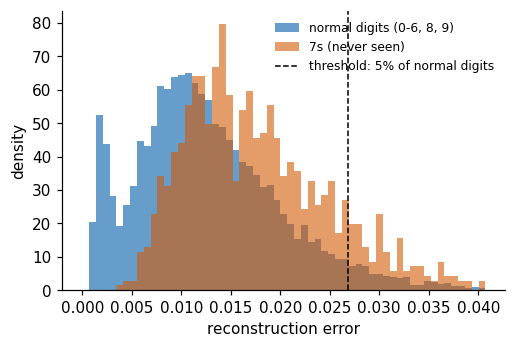

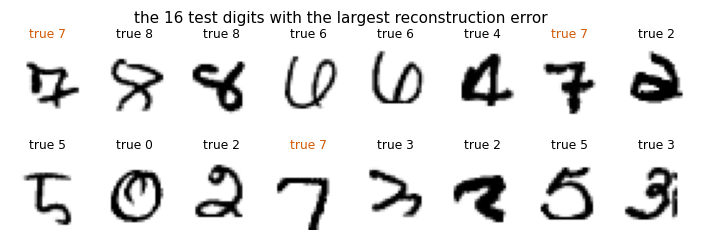

In [16]:
HELD_OUT = 7
aeA, _ = train_autoencoder(DenseAE(d=16, rngs=nnx.Rngs(5)), jnp.asarray(Xtr[ytr != HELD_OUT]), epochs=15, seed=5)
errA = errors(aeA, Xte_d)                                    # anomaly score of every test digit
is7 = yte == HELD_OUT
thr = float(np.percentile(errA[~is7], 95))                   # flags 5% of the normal test digits
nums["anom_err_normal"] = float(errA[~is7].mean())
nums["anom_err_seven"] = float(errA[is7].mean())
nums["anom_threshold"] = thr
nums["anom_frac7_flagged"] = float((errA[is7] > thr).mean())
top = np.argsort(errA)[::-1]
nums["anom_top16_sevens"] = int(is7[top[:16]].sum())
nums["anom_top100_sevens"] = int(is7[top[:100]].sum())
print(f"mean error: normal digits {nums['anom_err_normal']:.4f} | 7s {nums['anom_err_seven']:.4f}")
print(f"threshold (95th percentile of normal digits) {thr:.4f}: flags {nums['anom_frac7_flagged']:.3f} of the 7s")
print(f"fraction of 7s in the test set {is7.mean():.3f} | 7s among the 16 / 100 largest errors: "
      f"{nums['anom_top16_sevens']} / {nums['anom_top100_sevens']}")

fig, ax = plt.subplots(figsize=(5.2, 3.3))
bins = np.linspace(0, np.percentile(errA, 99.5), 60)
ax.hist(errA[~is7], bins=bins, density=True, alpha=0.6, color=UJBlue, label="normal digits (0-6, 8, 9)")
ax.hist(errA[is7], bins=bins, density=True, alpha=0.6, color=DSOrange, label="7s (never seen)")
ax.axvline(thr, color="k", ls="--", lw=1, label="threshold: 5% of normal digits")
ax.set_xlabel("reconstruction error"); ax.set_ylabel("density"); ax.legend(fontsize=8)
save(fig, "gen_anomaly_hist.png"); plt.show()

fig, axs = plt.subplots(2, 8, figsize=(8, 2.4))
for j, a in enumerate(axs.ravel()):
    t = top[j]
    a.imshow(Xte[t].reshape(28, 28), cmap="gray_r"); noframe(a)
    a.set_title(f"true {yte[t]}", fontsize=8, color=DSOrange if is7[t] else "k")
fig.suptitle("the 16 test digits with the largest reconstruction error", fontsize=10)
save(fig, "gen_anomaly_top.png"); plt.show()

The two histograms overlap strongly. A 7 shares strokes with 1s and 9s, which the network has seen, so many 7s are rebuilt well. Among the digits with the largest error some are 7s, others are badly written digits of the trained classes: for the autoencoder these are anomalies too.

### ROC curve and AUC

Every threshold $\tau$ gives one decision rule. For each we count

* the **true-positive rate** $\mathrm{TPR}(\tau)=\frac{\#\{\text{anomalies with } s>\tau\}}{\#\{\text{anomalies}\}}$: the fraction of anomalies (here the 7s) found;
* the **false-positive rate** $\mathrm{FPR}(\tau)=\frac{\#\{\text{normal samples with } s>\tau\}}{\#\{\text{normal samples}\}}$: the fraction of normal samples flagged, the false alarms.

Lowering $\tau$ from $+\infty$ to $-\infty$ traces the **ROC curve** (receiver operating characteristic) $\big(\mathrm{FPR}(\tau),\mathrm{TPR}(\tau)\big)$ from $(0,0)$ to $(1,1)$. A useless score lies on the diagonal (as many false alarms as hits); a perfect one goes straight up to $\mathrm{TPR}=1$ at $\mathrm{FPR}=0$.

The **AUC** is the area under the ROC curve. It does not depend on any threshold, and it has a simple probabilistic meaning: if $s_+$ is the score of a randomly chosen anomaly and $s_-$ that of a randomly chosen normal sample,
$$
\mathrm{AUC}=P(s_+>s_-)+\tfrac12P(s_+=s_-) =\frac{1}{n_+n_-}\sum_{a\in+}\sum_{b\in-}\Big[\mathbb 1(s_a>s_b)+\tfrac12\mathbb 1(s_a=s_b)\Big].
$$
$\mathrm{AUC}=\tfrac12$ for chance, $1$ for a perfect separation. (This is the Mann–Whitney $U$ statistic divided by $n_+n_-$.)

We compute the ROC curve by hand: sort the samples by decreasing score; walking down the sorted list is lowering the threshold, and the cumulative counts of anomalies and normal samples give TPR and FPR. The area follows from the trapezoidal rule. We check it against the pairwise formula, a single vectorised comparison of all $n_+\times n_-$ pairs.

AUC (trapezoid on the ROC curve) = 0.6958  |  AUC (all 1028 x 8972 pairs) = 0.6958


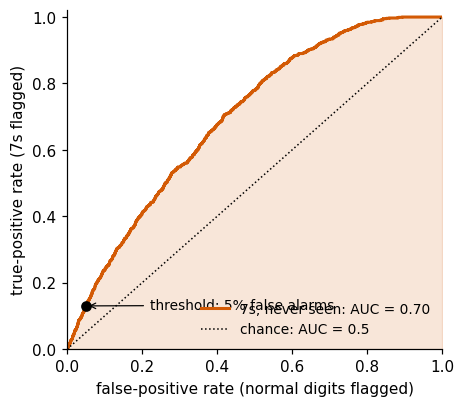

In [17]:
def roc_curve(scores, labels):
    """ROC curve of `scores` for binary `labels` (1 = anomaly). Returns FPR, TPR (from (0,0) to (1,1)) and the thresholds."""
    s, y = jnp.asarray(scores), jnp.asarray(labels, dtype=jnp.float32)
    order = jnp.argsort(-s)                                  # decreasing score = decreasing threshold
    s, y = s[order], y[order]
    tp, fp = jnp.cumsum(y), jnp.cumsum(1.0 - y)              # counts above the threshold placed after each sample
    last_of_tie = jnp.append(s[1:] != s[:-1], True)          # equal scores: one threshold, one point
    tpr = jnp.concatenate([jnp.zeros(1), tp[last_of_tie] / y.sum()])
    fpr = jnp.concatenate([jnp.zeros(1), fp[last_of_tie] / (1.0 - y).sum()])
    return np.asarray(fpr), np.asarray(tpr), np.asarray(s[last_of_tie])

def auc_trapezoid(fpr, tpr):
    return float(jnp.trapezoid(jnp.asarray(tpr), jnp.asarray(fpr)))

@jax.jit
def auc_pairwise(s_pos, s_neg):
    """P(s+ > s-) + P(s+ = s-)/2 over all pairs (Mann-Whitney)."""
    diff = s_pos[:, None] - s_neg[None, :]
    return jnp.mean((diff > 0) + 0.5 * (diff == 0))

fpr, tpr, _ = roc_curve(errA, is7)
nums["anom_auc"] = auc_trapezoid(fpr, tpr)
auc_pairs = float(auc_pairwise(jnp.asarray(errA[is7]), jnp.asarray(errA[~is7])))
print(f"AUC (trapezoid on the ROC curve) = {nums['anom_auc']:.4f}  |  AUC (all {is7.sum()} x {(~is7).sum()} pairs) = {auc_pairs:.4f}")

fig, ax = plt.subplots(figsize=(4.4, 4.0))
ax.fill_between(fpr, tpr, color=DSOrange, alpha=0.15)
ax.plot(fpr, tpr, color=DSOrange, lw=2, label=f"7s, never seen: AUC = {nums['anom_auc']:.2f}")
ax.plot([0, 1], [0, 1], "k:", lw=1, label="chance: AUC = 0.5")
ax.plot(0.05, nums["anom_frac7_flagged"], "o", color="k", ms=6)
ax.annotate("threshold: 5% false alarms", (0.05, nums["anom_frac7_flagged"]), xytext=(0.22, 0.12), fontsize=9,
            arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_xlabel("false-positive rate (normal digits flagged)"); ax.set_ylabel("true-positive rate (7s flagged)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.legend(fontsize=9, loc="lower right")
save(fig, "gen_anomaly_roc.png"); plt.show()

The black dot is the decision rule of the histogram: at $5\%$ false alarms it finds the fraction of 7s printed above.

*Optional cross-check* with scikit-learn's implementation (skipped if scikit-learn is not installed):

In [18]:
try:
    from sklearn.metrics import roc_auc_score
    print("scikit-learn AUC:", round(float(roc_auc_score(is7, errA)), 4), "| ours:", round(nums["anom_auc"], 4))
except ImportError:
    print("scikit-learn not available")

scikit-learn AUC: 0.6958 | ours: 0.6958


**Try it.** Hold out another digit instead of the 7 (change `HELD_OUT`). Which digits are easy anomalies and which are hard? Can you relate this to the shapes of the digits?

**Try it.** Use the deep convolutional autoencoder for the anomaly score. Does a model that rebuilds digits better also detect the 7s better?

<hr/>
## 8. CIFAR-10: photographs

CIFAR-10 (Lecture 4) contains $32\times32$ colour photographs in $10$ classes, $50\,000$ for training and $10\,000$ for testing, so $D=32\cdot32\cdot3=3072$. Each image is stored as one row of $3072$ bytes: first the $1024$ red values, then the green, then the blue, each in row-major order. The files are Python pickles; we read them with `pickle` and `numpy`.

train (50000, 3072) test (10000, 3072)


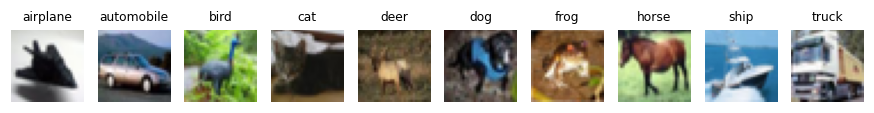

In [19]:
CIFAR_DIR = "data/cifar-10-batches-py"
if not os.path.isdir(CIFAR_DIR):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz", "data/cifar-10-python.tar.gz")
    with tarfile.open("data/cifar-10-python.tar.gz") as tf:
        tf.extractall("data")

def cifar_batch(name):
    with open(os.path.join(CIFAR_DIR, name), "rb") as fh:
        d = pickle.load(fh, encoding="bytes")
    return d[b"data"].astype(np.float32) / 255.0, np.array(d[b"labels"])

parts = [cifar_batch(f"data_batch_{i}") for i in range(1, 6)]
Ctr = np.concatenate([p[0] for p in parts]); cytr = np.concatenate([p[1] for p in parts])
Cte, cyte = cifar_batch("test_batch")
cnames = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
to_img = lambda v: v.reshape(3, 32, 32).transpose(1, 2, 0)        # (3072,) -> (32, 32, 3) for plotting
rc = np.random.default_rng(5)
csel = rc.choice(len(Cte), 5000, replace=False)
C5, cy5 = Cte[csel], cyte[csel]
print("train", Ctr.shape, "test", Cte.shape)

fig, axs = plt.subplots(1, 10, figsize=(10, 1.4))
for c in range(10):
    axs[c].imshow(to_img(Ctr[np.flatnonzero(cytr == c)[0]])); axs[c].set_title(cnames[c], fontsize=8); axs[c].axis("off")
plt.show()

### An autoencoder on CIFAR-10

The same dense architecture, scaled up: $3072\to512\to128\to32$ and back, $10$ epochs. Reconstructions from $32$ latent numbers, and a t-SNE map of the latent vectors of $5000$ test photographs (colours: classes, used only for plotting).

  epoch   1: training loss 0.03776   (  5.3 s)


  epoch   5: training loss 0.01792   ( 21.9 s)


  epoch  10: training loss 0.01620   ( 41.9 s)


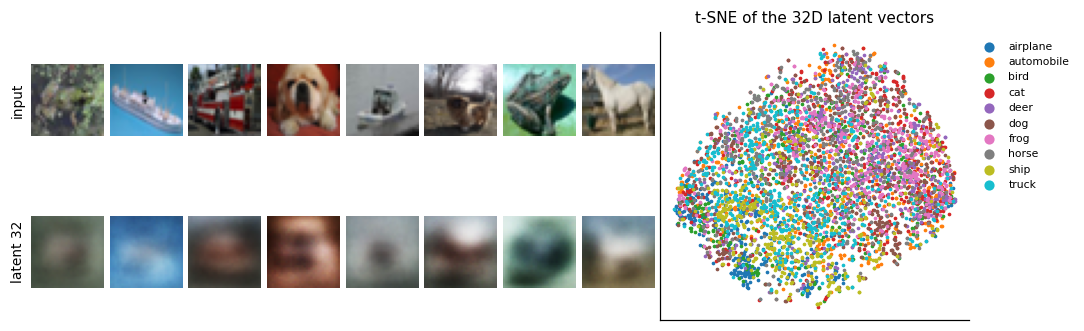

{'cifar_ae_test_mse': 0.0164, 'cifar_ae_latent_kmeans_ari_tsne': 0.0376}


In [20]:
Ctr_d, C5_d = jnp.asarray(Ctr), jnp.asarray(C5)
aeC, _ = train_autoencoder(DenseAE(d=32, D=3072, hidden=(512, 128), rngs=nnx.Rngs(6)), Ctr_d, epochs=10, seed=6)
LC = encode(aeC, C5_d)
RC = reconstruct(aeC, C5_d[:8])
nums["cifar_ae_test_mse"] = float(errors(aeC, C5_d).mean())
LC_tsne = tsne(LC)
nums["cifar_ae_latent_kmeans_ari_tsne"] = kmeans_ari(LC_tsne, cy5)

fig = plt.figure(figsize=(11, 3.4)); gs = fig.add_gridspec(2, 12, wspace=0.08, hspace=0.12)
for j in range(8):
    for r, src in enumerate([C5[j], RC[j]]):
        a = fig.add_subplot(gs[r, j]); a.imshow(np.clip(to_img(src), 0, 1)); noframe(a)
        if j == 0: a.set_ylabel(["input", "latent 32"][r], fontsize=9)
a = fig.add_subplot(gs[:, 8:])
for c in range(10):
    m = cy5 == c
    a.scatter(LC_tsne[m, 0], LC_tsne[m, 1], s=2, color=cmap10(c), label=cnames[c])
a.set_title("t-SNE of the 32D latent vectors", fontsize=10); a.set_xticks([]); a.set_yticks([])
a.legend(markerscale=4, fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
save(fig, "gen_cifar_ae.png"); plt.show()
print({k: round(nums[k], 4) for k in ["cifar_ae_test_mse", "cifar_ae_latent_kmeans_ari_tsne"]})

The reconstructions keep the colours and the coarse layout of the scene but lose the details, and the classes do not separate in the latent space: two photographs of the same class can differ in almost every pixel (pose, background, lighting), and a pixel-wise loss puts them far apart.

**Try it.** Compare with MNIST: why are the CIFAR-10 classes so much harder to separate from the pixels? Train the CNN of Lecture 4 and run t-SNE on its last hidden layer instead.

### Anomaly detection: a clear case

The 7s were a subtle anomaly. Now a very different input: the dense autoencoder trained on **all** MNIST digits ($d=16$, `ae16` from Section 4) receives CIFAR-10 photographs, converted to grayscale with the luminance weights $0.299R+0.587G+0.114B$ and resized from $32\times32$ to $28\times28$ with `jax.image.resize` (bilinear interpolation). The normal samples are the $10\,000$ MNIST test digits, the anomalies the first $5000$ CIFAR-10 test photographs; the threshold again flags $5\%$ of the normal samples.

threshold 0.0256 flags 0.9984 of the photographs
AUC (trapezoid) 0.9997 | AUC (pairs) 0.9997
median error: digits 0.0110 | photographs 0.2191


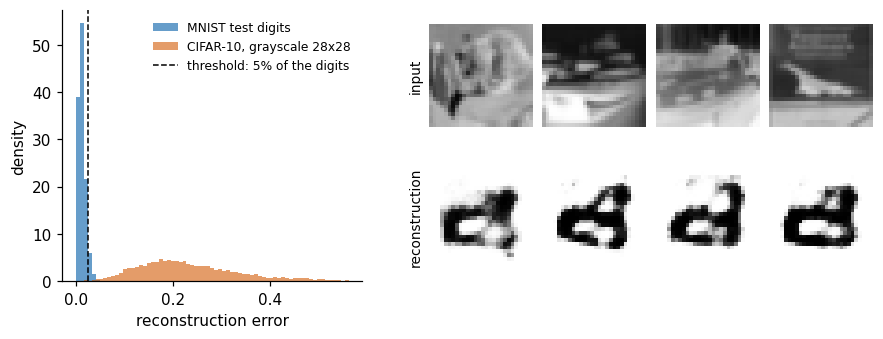

In [21]:
gray = 0.299 * Cte[:5000, :1024] + 0.587 * Cte[:5000, 1024:2048] + 0.114 * Cte[:5000, 2048:]
ood = jax.image.resize(jnp.asarray(gray).reshape(-1, 32, 32), (5000, 28, 28), method="bilinear").reshape(-1, 784)
ood = jnp.clip(ood, 0.0, 1.0)

err_in = errors(ae16, Xte_d)                                 # normal: MNIST test digits
err_ood = errors(ae16, ood)                                  # anomalies: photographs
thr_in = float(np.percentile(err_in, 95))
nums["ood_threshold"] = thr_in
nums["ood_frac_flagged"] = float((err_ood > thr_in).mean())
fpr_o, tpr_o, _ = roc_curve(np.r_[err_in, err_ood], np.r_[np.zeros(len(err_in)), np.ones(len(err_ood))])
nums["ood_auc"] = auc_trapezoid(fpr_o, tpr_o)
nums["ood_auc_pairwise"] = float(auc_pairwise(jnp.asarray(err_ood), jnp.asarray(err_in)))
nums["ood_median_err_digits"] = float(np.median(err_in))
nums["ood_median_err_photos"] = float(np.median(err_ood))
print(f"threshold {thr_in:.4f} flags {nums['ood_frac_flagged']:.4f} of the photographs")
print(f"AUC (trapezoid) {nums['ood_auc']:.4f} | AUC (pairs) {nums['ood_auc_pairwise']:.4f}")
print(f"median error: digits {nums['ood_median_err_digits']:.4f} | photographs {nums['ood_median_err_photos']:.4f}")

rec_ood = reconstruct(ae16, ood[:4])
fig = plt.figure(figsize=(9.5, 3.2))
gs = fig.add_gridspec(2, 6, width_ratios=[1.6, 0.25, 0.55, 0.55, 0.55, 0.55], wspace=0.08, hspace=0.08)
ax = fig.add_subplot(gs[:, 0])
bins = np.linspace(0, np.percentile(np.r_[err_in, err_ood], 99.5), 70)
ax.hist(err_in, bins=bins, density=True, alpha=0.6, color=UJBlue, label="MNIST test digits")
ax.hist(err_ood, bins=bins, density=True, alpha=0.6, color=DSOrange, label="CIFAR-10, grayscale 28x28")
ax.axvline(thr_in, color="k", ls="--", lw=1, label="threshold: 5% of the digits")
ax.set_xlabel("reconstruction error"); ax.set_ylabel("density"); ax.legend(fontsize=8)
for j in range(4):
    for r, src in enumerate([np.asarray(ood[j]), rec_ood[j]]):
        a = fig.add_subplot(gs[r, 2 + j]); a.imshow(src.reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
        noframe(a)
        if j == 0: a.set_ylabel(["input", "reconstruction"][r], fontsize=9)
save(fig, "gen_anomaly_ood.png"); plt.show()

The two populations barely overlap, and the reconstructions of the photographs look like blurred digits: the decoder can only produce what it has learned.

**An anomaly far from the training data is easy to detect; one that resembles it is hard.** The two ROC curves side by side:

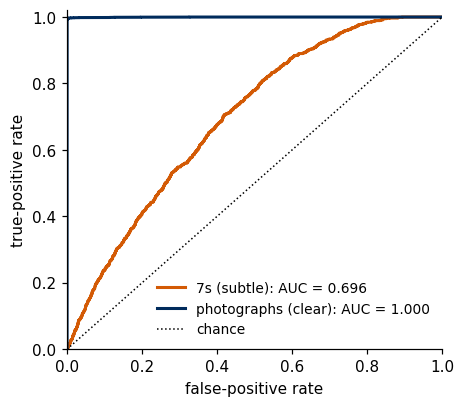

In [22]:
fig, ax = plt.subplots(figsize=(4.4, 4.0))
ax.plot(fpr, tpr, color=DSOrange, lw=2, label=f"7s (subtle): AUC = {nums['anom_auc']:.3f}")
ax.plot(fpr_o, tpr_o, color=UJNavy, lw=2, label=f"photographs (clear): AUC = {nums['ood_auc']:.3f}")
ax.plot([0, 1], [0, 1], "k:", lw=1, label="chance")
ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(fontsize=9, loc="lower right"); plt.show()

### The idea in one figure

The autoencoder trained on all digits rebuilds a digit well: small reconstruction error. A photograph is unlike anything it was trained on: the decoder can only produce digit-like images, the error is large, and the photograph is flagged. We show a typical case of each: the digit and the photograph whose errors are the medians of their groups. The two error maps share one colour scale.

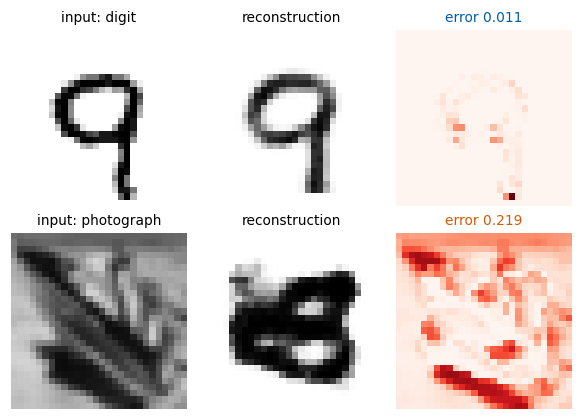

errors shown: 0.011 0.2191


In [23]:
kd = np.argsort(err_in)[len(err_in) // 2]                    # median digit
ko = np.argsort(err_ood)[len(err_ood) // 2]                  # median photograph
xd_, xo_ = Xte[kd], np.asarray(ood[ko])
rd_, ro_ = reconstruct(ae16, Xte_d[kd:kd + 1])[0], reconstruct(ae16, ood[ko:ko + 1])[0]
vmax = max(((xd_ - rd_) ** 2).max(), ((xo_ - ro_) ** 2).max())

fig, axs = plt.subplots(2, 3, figsize=(5.4, 3.9))
for r, (xin, xr, e, lab) in enumerate([(xd_, rd_, err_in[kd], "digit"), (xo_, ro_, err_ood[ko], "photograph")]):
    for c, (im, cm) in enumerate([(xin, "gray_r"), (xr, "gray_r"), ((xin - xr) ** 2, "Reds")]):
        axs[r, c].imshow(im.reshape(28, 28), cmap=cm, vmin=0, vmax=(vmax if c == 2 else 1)); axs[r, c].axis("off")
    axs[r, 0].set_title(f"input: {lab}", fontsize=9); axs[r, 1].set_title("reconstruction", fontsize=9)
    axs[r, 2].set_title(f"error {e:.3f}", fontsize=9, color=(DSOrange if r else UJBlue))
plt.tight_layout(); save(fig, "gen_anomaly_idea.png"); plt.show()
nums["idea_err_digit"] = float(err_in[kd]); nums["idea_err_photo"] = float(err_ood[ko])
print("errors shown:", round(nums["idea_err_digit"], 4), round(nums["idea_err_photo"], 4))

**Try it.** Feed the MNIST autoencoder other inputs: digits rotated by $90°$, inverted images $1-\mathbf x$, uniform noise, or the Fashion-MNIST clothes. Order them by their AUC against the MNIST test digits.

**Try it.** The reconstruction error is not the only possible score. Fit a Gaussian to the latent vectors $\mathbf z$ of the training digits and use the Mahalanobis distance of $\mathbf z$ as the score. Is it better for the 7s?

<hr/>
## 9. Summary

* An autoencoder is an encoder and a decoder trained together to rebuild their input through a bottleneck of $d$ numbers; the loss is the pixel-wise MSE, no labels are needed.
* The bottleneck is a learned, lossy compression. A linear autoencoder spans the PCA subspace; non-linear layers compress better than any projection.
* The latent space keeps the structure of the data (similar images, nearby $\mathbf z$), but its geometry is not designed for clustering. Convolutional encoders, which see neighbouring pixels, separate the digits better.
* The reconstruction error of an autoencoder trained on normal data is an anomaly score. The ROC curve shows all thresholds at once; the AUC is the probability that an anomaly scores higher than a normal sample.
* Anomalies far from the training data (photographs for an MNIST autoencoder) are easy to detect; anomalies that resemble the training data (a held-out digit) are hard.

The numbers quoted on the slides are saved below.

In [24]:
nums["runtime_s"] = round(time.time() - t_start, 1)
with open(f"{OUT}/numbers_lab017.json", "w") as fh:
    json.dump(nums, fh, indent=1)
for k, v in nums.items():
    print(f"{k:38s} {np.round(v, 4) if not isinstance(v, int) else v}")
print(f"\ntotal runtime {nums['runtime_s'] / 60:.1f} min")

ae2_test_mse                           0.0389
ae16_test_mse                          0.0121
pca2_test_mse                          0.0557
pca2_train_mse_from_eigenvalues        0.056
pca16_test_mse                         0.0268
pca16_train_mse_from_eigenvalues       0.0273
linear_ae2_test_mse                    0.0557
linear_ae2_principal_angles_deg        [0.761  0.9732]
pixels_pca50_kmeans_ari                0.3839
ae16_latent_kmeans_ari_direct          0.2838
ae16_latent_kmeans_ari_tsne            0.6963
cae2_test_mse                          0.0445
ae2_latent_kmeans_ari                  0.2409
cae2_latent_kmeans_ari                 0.2684
dcae16_test_mse                        0.0121
dcae16_pca2_var                        0.3886
dcae16_kmeans_ari_direct               0.4558
dcae16_kmeans_ari_tsne                 0.8153
anom_err_normal                        0.0128
anom_err_seven                         0.0179
anom_threshold                         0.0268
anom_frac7_flagged        